# Imprting Libraries

In [334]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, SimpleRNN, LSTM, GRU, Embedding, Dropout, Bidirectional
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.metrics import confusion_matrix

# Load Dataset

In [335]:
df=load_dataset('dair-ai/emotion')

In [336]:
train_text=df['train']['text']
train_label=df['train']['label']

In [337]:
val_text=df['validation']['text']
val_label=df['validation']['label']

In [338]:
test_text=df['test']['text']
test_label=df['test']['label']

In [339]:
label_names=df['train'].features['label'].names
label_names

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

In [340]:
df_train = pd.DataFrame(
    {
        'text'  : train_text,
        'label' : [label_names[i] for i in train_label]
    }
)

df_val = pd.DataFrame(
    {
        'text'  : val_text,
        'label' : [label_names[i] for i in val_label]
    }
)

df_test = pd.DataFrame(
    {
        'text'  : test_text,
        'label' : [label_names[i] for i in test_label]
    }
)

In [341]:
df_train.head()

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


In [342]:
df_val.head()

,text,label
0,im feeling quite sad and sorry for myself but ...,sadness
1,i feel like i am still looking at a blank canv...,sadness
2,i feel like a faithful servant,love
3,i am just feeling cranky and blue,anger
4,i can have for a treat or if i am feeling festive,joy


In [343]:
df_test.head()

,text,label
0,im feeling rather rotten so im not very ambiti...,sadness
1,im updating my blog because i feel shitty,sadness
2,i never make her separate from me because i do...,sadness
3,i left with my bouquet of red and yellow tulip...,joy
4,i was feeling a little vain when i did this one,sadness


# EDA

In [344]:
order=df_train['label'].value_counts().index

<Axes: xlabel='label', ylabel='count'>

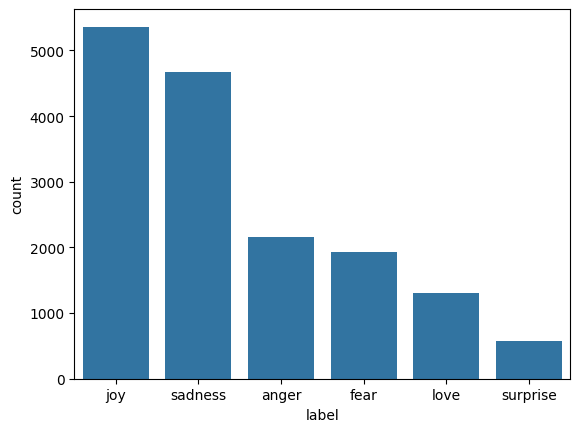

In [345]:
sns.countplot(data=df_train,x='label',order=order)

# Data Preprocessing

In [346]:
max_words=12000

In [347]:
tokenizer=Tokenizer(num_words=max_words,oov_token='<ukn>')
tokenizer.fit_on_texts(df_train['text'])
train_sequence=tokenizer.texts_to_sequences(df_train['text'])
val_sequence=tokenizer.texts_to_sequences(df_val['text'])
test_sequence=tokenizer.texts_to_sequences(df_test['text'])

In [348]:
max_len=max([len(seq) for seq in train_sequence])
padded_train_sequence = pad_sequences(train_sequence,maxlen=max_len,padding='post', truncating='post')
padded_val_sequence = pad_sequences(val_sequence,maxlen=max_len,padding='post', truncating='post')
padded_test_sequence = pad_sequences(test_sequence ,maxlen=max_len,padding='post', truncating='post')

In [349]:
train_labels = np.array(train_label)
val_labels = np.array(val_label)
test_labels  = np.array(test_label)

In [350]:
num_classes = len(np.unique(train_labels))

# Assiginning Class Weight
due to class imbalance problem

In [351]:
from sklearn.utils import class_weight

class_weights=class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_labels),
    y=train_labels
)

class_weight_dict=dict(enumerate(class_weights))

In [352]:
class_weight_dict

{0: np.float64(0.5715102157451064),
 1: np.float64(0.49732686808404825),
 2: np.float64(2.044989775051125),
 3: np.float64(1.2351397251814111),
 4: np.float64(1.3766993632765445),
 5: np.float64(4.662004662004662)}

# Foundational Models

## Simple RNN

In [353]:
rnn=Sequential()

In [354]:
rnn.add(Input(shape=(max_len,)))
rnn.add(Embedding(input_dim=max_words, output_dim=128))
rnn.add(SimpleRNN(units=128, return_sequences=True))
rnn.add(Dropout(0.3))
rnn.add(SimpleRNN(units=64))
rnn.add(Dropout(0.3))
rnn.add(Dense(units=num_classes, activation='softmax'))

In [355]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

In [356]:
checkpoint_path = '/content/rnn_model.keras'

rnn_checkpoint = ModelCheckpoint(
    checkpoint_path,
    monitor='val_loss',
    verbose=1,
    save_best_only=True,
    mode='min'
)

In [357]:
rnn.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [358]:
rnn.summary()

Model: "sequential_24"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_24 (Embedding)        │ (None, 66, 128)        │     1,536,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_8 (SimpleRNN)        │ (None, 66, 128)        │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_48 (Dropout)            │ (None, 66, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_9 (SimpleRNN)        │ (None, 64)             │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_49 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,581,638 (6.03 MB)

 Trainable params: 1,581,638 (6.03 MB)

 Non-trainable params: 0 (0.00 B)

In [359]:
rnn.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_val_sequence, val_labels),
    epochs = 25,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping,rnn_checkpoint]
)

Epoch 1/25
498/500 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.1734 - loss: 1.9683
Epoch 1: val_loss improved from None to 1.84242, saving model to /content/rnn_model.keras

Epoch 1: finished saving model to /content/rnn_model.keras
500/500 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - accuracy: 0.1674 - loss: 1.9674 - val_accuracy: 0.0450 - val_loss: 1.8424
Epoch 2/25
497/500 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.1598 - loss: 1.8970
Epoch 2: val_loss improved from 1.84242 to 1.78519, saving model to /content/rnn_model.keras

Epoch 2: finished saving model to /content/rnn_model.keras
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.1553 - loss: 1.8757 - val_accuracy: 0.3515 - val_loss: 1.7852
Epoch 3/25
498/500 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.1523 - loss: 1.8363
Epoch 3: val_loss did not improve from 1.78519
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.1476 - loss: 1.8359 - val_accuracy: 0.0450 - val_loss: 1.8802
Epoch 4/25
500/500 ━━━━━━━━━━━━━━━

In [360]:
rnn_loss, rnn_accuracy = rnn.evaluate(padded_test_sequence, test_labels)
print(f"RNN Loss: {rnn_loss}")
print(f"RNN Accuracy: {rnn_accuracy}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1145 - loss: 1.7580
RNN Loss: 1.7579922676086426
RNN Accuracy: 0.1145000010728836


## LSTM

In [361]:
lstm=Sequential()

In [362]:
lstm.add(Input(shape=(max_len,)))
lstm.add(Embedding(input_dim=max_words, output_dim=128))
lstm.add(LSTM(units=128, return_sequences=True))
lstm.add(Dropout(0.3))
lstm.add(LSTM(units=64))
lstm.add(Dropout(0.3))
lstm.add(Dense(units=num_classes, activation='softmax'))

In [363]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

In [364]:
checkpoint_path_lstm = '/content/lstm_model.keras'

lstm_checkpoint = ModelCheckpoint(
    checkpoint_path_lstm,
    monitor='val_loss',
    verbose=1,
    save_best_only=True,
    mode='min'
)

In [365]:
lstm.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [366]:
lstm.summary()

Model: "sequential_25"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_25 (Embedding)        │ (None, 66, 128)        │     1,536,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_20 (LSTM)                  │ (None, 66, 128)        │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_50 (Dropout)            │ (None, 66, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_21 (LSTM)                  │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_51 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,717,382 (6.55 MB)

 Trainable params: 1,717,382 (6.55 MB)

 Non-trainable params: 0 (0.00 B)

In [367]:
lstm.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_val_sequence, val_labels),
    epochs = 25,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping,lstm_checkpoint]
)

Epoch 1/25
496/500 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.2010 - loss: 1.7675
Epoch 1: val_loss improved from None to 1.79969, saving model to /content/lstm_model.keras

Epoch 1: finished saving model to /content/lstm_model.keras
500/500 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.1599 - loss: 1.7947 - val_accuracy: 0.2750 - val_loss: 1.7997
Epoch 2/25
498/500 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1278 - loss: 1.8091
Epoch 2: val_loss did not improve from 1.79969
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.1477 - loss: 1.7934 - val_accuracy: 0.0405 - val_loss: 1.8071
Epoch 3/25
495/500 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1306 - loss: 1.7905
Epoch 3: val_loss improved from 1.79969 to 1.78749, saving model to /content/lstm_model.keras

Epoch 3: finished saving model to /content/lstm_model.keras
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.1483 - loss: 1.7932 - val_accuracy: 0.1385 - val_loss: 1.7875
Epoch 4/25
499/500 ━━━━━━━━━━━━

In [368]:
lstm_loss, lstm_accuracy = lstm.evaluate(padded_test_sequence, test_labels)
print(f"LSTM Loss: {lstm_loss}")
print(f"LSTM Accuracy: {lstm_accuracy}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.1380 - loss: 1.7872
LSTM Loss: 1.7871553897857666
LSTM Accuracy: 0.1379999965429306


## GRU

In [369]:
gru=Sequential()

In [370]:
gru.add(Input(shape=(max_len,)))
gru.add(Embedding(input_dim=max_words, output_dim=128))
gru.add(GRU(units=128, return_sequences=True))
gru.add(Dropout(0.3))
gru.add(GRU(units=64))
gru.add(Dropout(0.3))
gru.add(Dense(units=num_classes, activation='softmax'))

In [371]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

In [372]:
checkpoint_path_gru = '/content/gru_model.keras'

gru_checkpoint = ModelCheckpoint(
    checkpoint_path_gru,
    monitor='val_loss',
    verbose=1,
    save_best_only=True,
    mode='min'
)

In [373]:
gru.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [374]:
gru.summary()

Model: "sequential_26"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_26 (Embedding)        │ (None, 66, 128)        │     1,536,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_20 (GRU)                    │ (None, 66, 128)        │        99,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_52 (Dropout)            │ (None, 66, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_21 (GRU)                    │ (None, 64)             │        37,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_53 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,672,710 (6.38 MB)

 Trainable params: 1,672,710 (6.38 MB)

 Non-trainable params: 0 (0.00 B)

In [375]:
gru.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_val_sequence, val_labels),
    epochs = 25,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping,gru_checkpoint]
)

Epoch 1/25
496/500 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1552 - loss: 1.7972
Epoch 1: val_loss improved from None to 1.77555, saving model to /content/gru_model.keras

Epoch 1: finished saving model to /content/gru_model.keras
500/500 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.1447 - loss: 1.7952 - val_accuracy: 0.3520 - val_loss: 1.7756
Epoch 2/25
497/500 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.2110 - loss: 1.7719
Epoch 2: val_loss did not improve from 1.77555
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.1629 - loss: 1.7933 - val_accuracy: 0.3520 - val_loss: 1.7773
Epoch 3/25
496/500 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1854 - loss: 1.7755
Epoch 3: val_loss did not improve from 1.77555
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.1608 - loss: 1.7944 - val_accuracy: 0.1375 - val_loss: 1.8110
Epoch 4/25
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1060 - loss: 1.8117
Epoch 4: val_loss did not improve from 1.77555
500/500

In [376]:
gru_loss, gru_accuracy = gru.evaluate(padded_test_sequence, test_labels)
print(f"GRU Loss: {gru_loss}")
print(f"GRU Accuracy: {gru_accuracy}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.3475 - loss: 1.7753
GRU Loss: 1.775345802307129
GRU Accuracy: 0.3474999964237213


## Comparing

In [377]:
result_df = pd.DataFrame({
    'Model' : ['RNN', 'LSTM', 'GRU'],
    'Test Loss': [rnn_loss, lstm_loss, gru_loss],
    'Test Accuracy': [rnn_accuracy, lstm_accuracy, gru_accuracy]
    }).sort_values(by='Test Accuracy',ascending=False)
result_df

,Model,Test Loss,Test Accuracy
2,GRU,1.775346,0.3475
1,LSTM,1.787155,0.1380
0,RNN,1.757992,0.1145


# Bidirectional Models

## BiGRU

In [378]:
BiGRU=Sequential()

In [379]:
BiGRU.add(Input(shape=(max_len,)))
BiGRU.add(Embedding(input_dim=max_words, output_dim=256))
BiGRU.add(Bidirectional(GRU(units=128, return_sequences=True)))
BiGRU.add(Dropout(0.3))
BiGRU.add(Bidirectional(GRU(units=64)))
BiGRU.add(Dropout(0.3))
BiGRU.add(Dense(units=num_classes, activation='softmax'))

In [380]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

In [381]:
checkpoint_path_bigru = '/content/bigru_model.keras'

bigru_checkpoint = ModelCheckpoint(
    checkpoint_path_bigru,
    monitor='val_loss',
    verbose=1,
    save_best_only=True,
    mode='min'
)

In [382]:
BiGRU.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [383]:
BiGRU.summary()

Model: "sequential_27"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_27 (Embedding)        │ (None, 66, 256)        │     3,072,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_24                │ (None, 66, 256)        │       296,448 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_54 (Dropout)            │ (None, 66, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_25                │ (None, 128)            │       123,648 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_55 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,492,870 (13.32 MB)

 Trainable params: 3,492,870 (13.32 MB)

 Non-trainable params: 0 (0.00 B)

In [384]:
BiGRU_history=BiGRU.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_val_sequence, val_labels),
    epochs = 25,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping,bigru_checkpoint]
)

Epoch 1/25
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.3093 - loss: 1.5467
Epoch 1: val_loss improved from None to 0.28070, saving model to /content/bigru_model.keras

Epoch 1: finished saving model to /content/bigru_model.keras
500/500 ━━━━━━━━━━━━━━━━━━━━ 12s 19ms/step - accuracy: 0.5528 - loss: 1.0952 - val_accuracy: 0.9040 - val_loss: 0.2807
Epoch 2/25
498/500 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9203 - loss: 0.2247
Epoch 2: val_loss improved from 0.28070 to 0.20459, saving model to /content/bigru_model.keras

Epoch 2: finished saving model to /content/bigru_model.keras
500/500 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.9254 - loss: 0.1992 - val_accuracy: 0.9230 - val_loss: 0.2046
Epoch 3/25
498/500 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9501 - loss: 0.1240
Epoch 3: val_loss did not improve from 0.20459
500/500 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.9497 - loss: 0.1246 - val_accuracy: 0.9295 - val_loss: 0.2122
Epoch 4/25
499/500 ━━━━━━━

In [385]:
bigru_loss, bigru_accuracy = BiGRU.evaluate(padded_test_sequence, test_labels)
print(f"BiGRU Loss: {bigru_loss}")
print(f"BiGRU Accuracy: {bigru_accuracy}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9240 - loss: 0.2275
BiGRU Loss: 0.22751088440418243
BiGRU Accuracy: 0.9240000247955322


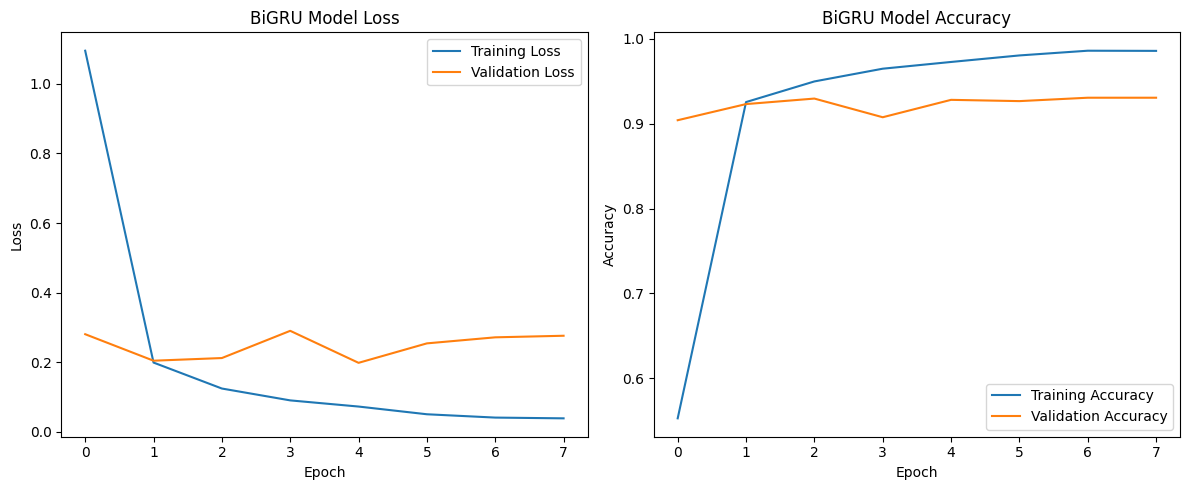

In [386]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(BiGRU_history.history['loss'], label='Training Loss')
plt.plot(BiGRU_history.history['val_loss'], label='Validation Loss')
plt.title('BiGRU Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(BiGRU_history.history['accuracy'], label='Training Accuracy')
plt.plot(BiGRU_history.history['val_accuracy'], label='Validation Accuracy')
plt.title('BiGRU Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend()

plt.tight_layout()
plt.show()

## BiLSTM

In [387]:
BiLSTM=Sequential()

In [388]:
BiLSTM.add(Input(shape=(max_len,)))
BiLSTM.add(Embedding(input_dim=max_words, output_dim=256))
BiLSTM.add(Bidirectional(LSTM(units=128, return_sequences=True)))
BiLSTM.add(Dropout(0.3))
BiLSTM.add(Bidirectional(LSTM(units=64)))
BiLSTM.add(Dropout(0.3))
BiLSTM.add(Dense(units=num_classes, activation='softmax'))

In [389]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

In [390]:
checkpoint_path_bilstm = '/content/bilstm_model.keras'

bilstm_checkpoint = ModelCheckpoint(
    checkpoint_path_bilstm,
    monitor='val_loss',
    verbose=1,
    save_best_only=True,
    mode='min'
)

In [391]:
BiLSTM.summary()

Model: "sequential_28"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_28 (Embedding)        │ (None, 66, 256)        │     3,072,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_26                │ (None, 66, 256)        │       394,240 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_56 (Dropout)            │ (None, 66, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_27                │ (None, 128)            │       164,352 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_57 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_28 (Dense)                │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,631,366 (13.85 MB)

 Trainable params: 3,631,366 (13.85 MB)

 Non-trainable params: 0 (0.00 B)

In [392]:
BiLSTM.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [393]:
BiLSTM_history=BiLSTM.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_val_sequence, val_labels),
    epochs = 25,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping,bilstm_checkpoint]
)

Epoch 1/25
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.3453 - loss: 1.4709
Epoch 1: val_loss improved from None to 0.37948, saving model to /content/bilstm_model.keras

Epoch 1: finished saving model to /content/bilstm_model.keras
500/500 ━━━━━━━━━━━━━━━━━━━━ 12s 19ms/step - accuracy: 0.5569 - loss: 1.0201 - val_accuracy: 0.8875 - val_loss: 0.3795
Epoch 2/25
499/500 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9185 - loss: 0.2502
Epoch 2: val_loss improved from 0.37948 to 0.25939, saving model to /content/bilstm_model.keras

Epoch 2: finished saving model to /content/bilstm_model.keras
500/500 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.9153 - loss: 0.2474 - val_accuracy: 0.9105 - val_loss: 0.2594
Epoch 3/25
498/500 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9387 - loss: 0.1589
Epoch 3: val_loss improved from 0.25939 to 0.23483, saving model to /content/bilstm_model.keras

Epoch 3: finished saving model to /content/bilstm_model.keras
500/500 ━━━━━━━━━━━━━━━━━━━━

In [394]:
bilstm_loss, bilstm_accuracy = BiLSTM.evaluate(padded_test_sequence, test_labels)
print(f"BiLSTM Loss: {bilstm_loss}")
print(f"BiLSTM Accuracy: {bilstm_accuracy}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9095 - loss: 0.2785
BiLSTM Loss: 0.2785417437553406
BiLSTM Accuracy: 0.909500002861023


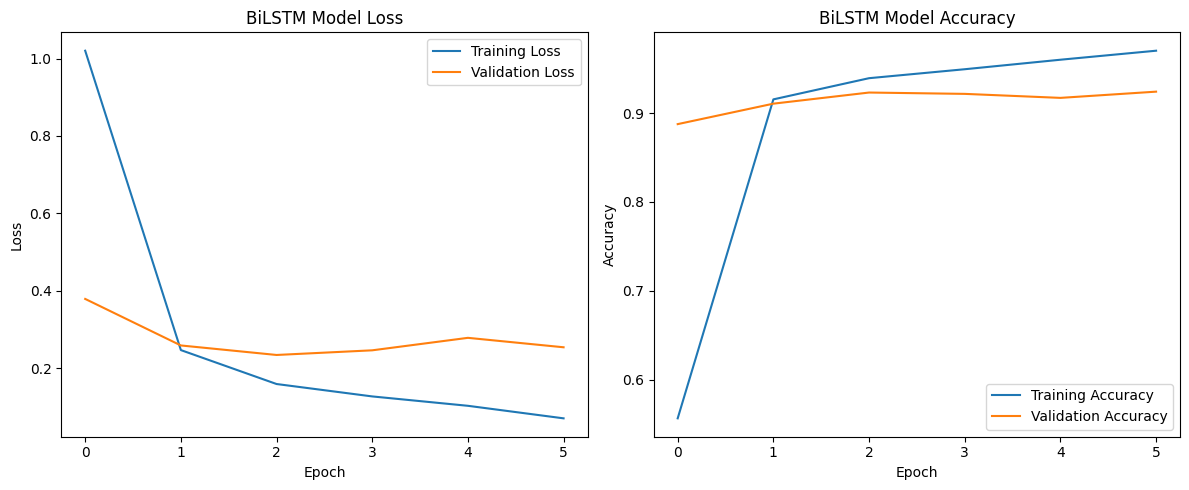

In [395]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(BiLSTM_history.history['loss'], label='Training Loss')
plt.plot(BiLSTM_history.history['val_loss'], label='Validation Loss')
plt.title('BiLSTM Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(BiLSTM_history.history['accuracy'], label='Training Accuracy')
plt.plot(BiLSTM_history.history['val_accuracy'], label='Validation Accuracy')
plt.title('BiLSTM Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend()

plt.tight_layout()
plt.show()

In [396]:
result_df_2 = pd.DataFrame({
    'Model' : ['BiGRU', 'BiLSTM'],
    'Test Loss': [bigru_loss, bilstm_loss],
    'Test Accuracy': [bigru_accuracy, bilstm_accuracy]
    }).sort_values(by='Test Accuracy',ascending=False)
result_df_2

,Model,Test Loss,Test Accuracy
0,BiGRU,0.227511,0.9240
1,BiLSTM,0.278542,0.9095


# Evaluation

In [397]:
bigru_pred=np.argmax(BiGRU.predict(padded_test_sequence),axis=1)
bigru_pred

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step


array([0, 0, 0, ..., 1, 1, 5])

In [398]:
cm=confusion_matrix(bigru_pred,test_labels)

<Axes: >

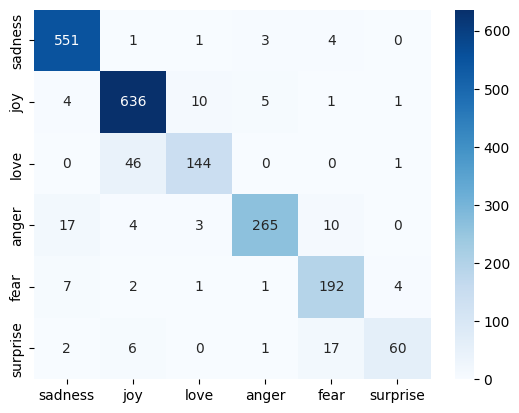

In [399]:
sns.heatmap(cm,annot=True, fmt='d', cmap='Blues', xticklabels=label_names, yticklabels=label_names)

# Testing

In [400]:
sample_texts = [
    "I can't believe how happy I am right now, this is amazing!",
    "I feel so alone and hopeless today.",
    "I am furious that they cancelled the trip at the last minute.",
    "I feel terrified when walking down dark alleyways alone.",
    "I was shocked and completely surprised by the unexpected gift!"
]

sample_sequences = tokenizer.texts_to_sequences(sample_texts)
sample_padded_sequences = pad_sequences(sample_sequences, maxlen=max_len, padding='post', truncating='post')

sample_predictions = np.argmax(BiGRU.predict(sample_padded_sequences), axis=1)

for i in range(len(sample_texts)):
  print(f'Text: {sample_texts[i]}\nPredicted Emotion: {label_names[sample_predictions[i]]}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
Text: I can't believe how happy I am right now, this is amazing!
Predicted Emotion: joy
Text: I feel so alone and hopeless today.
Predicted Emotion: sadness
Text: I am furious that they cancelled the trip at the last minute.
Predicted Emotion: anger
Text: I feel terrified when walking down dark alleyways alone.
Predicted Emotion: fear
Text: I was shocked and completely surprised by the unexpected gift!
Predicted Emotion: surprise


In [401]:
def predict_emotion(text):
  text_sequences=tokenizer.texts_to_sequences([text])
  text_padded_sequences=pad_sequences(text_sequences, maxlen=max_len, padding='post', truncating='post')
  prediction=np.argmax(BiGRU.predict(text_padded_sequences), axis=1)[0]
  print(f'Text: {text}\nPredicted Emotion: {label_names[prediction]}')

# Exporting Model

In [402]:
import os
import pickle

model_dir = 'Artifacts'
os.makedirs(model_dir, exist_ok=True)

#Save our BiGRU Model
BiGRU.save(os.path.join(model_dir, 'BiGRU_Model.keras'))

#Save the tokenizer model
with open(os.path.join(model_dir, 'tokenizer.pkl'), 'wb') as file:
  pickle.dump(tokenizer, file)